# Cortical Annotation Tool

## How to Use this Tool

This section should document how to use the annotation tool, generally.

## What to Annotate

This section should contain instructions for the specific contours or boundaries that are being drawn using the tool as part of the current annotation project.

The annotation tool is designed to be a general crowd-source tool for annotating the cortical surface. It is generally recommended to include some amount of instructions for anyone annotating cortices both to explain to the raters how annotations should be drawn and to document how the annotations were drawn for future researchers.

## The Annotation Tool

In [1]:
%%html
<!-- This HTML block inserts code into the notebook that hides the input
     blocks (such as this one) and the prompt panel (the space to the left 
     where "In [ ]" and "Out [ ]" appear).
-->
<script>
    $('div.prompt').hide();
    $('div.input').hide();
</script>

In [2]:
# This cell starts the Annotation Tool.
#
# All cells in this notebook are run auotmatically when the notebook starts in
# the docker container (if you are running this outside of the docker container
# you are on your own), and all input cells are automatically hidden from the
# user.
#
# First, we configure a few things (these are set up to work inside of the
# docker container).
config_path = '/config/config.yaml'
cache_path  = '/cache/tool'

import sys
sys.path.insert(0, '/src')

# Next, import the tool from the annotation library.
from annotate import AnnotationTool
# Then, we just start the tool.
# The tool displays itself during its init function (so that it can display a
# loading screen), so we capture this output.
tool = AnnotationTool(config_path=config_path, cache_path=cache_path)

Matplotlib created a temporary config/cache directory at /tmp/matplotlib-p35c_tl9 because the default path (/home/jovyan/.cache/matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


AnnotationTool(children=(ControlPanel(children=(HTML(value='\n            <style>\n            .jupyter-widget…

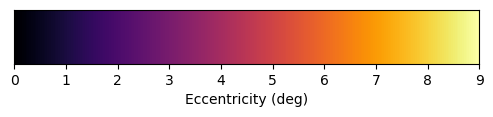

In [3]:
import matplotlib.pyplot as plt, numpy as np
MAXECC = 9  # same value as in the config
fig, ax = plt.subplots(figsize=(6, 0.7))
ax.imshow(np.linspace(0, 1, 256)[None, :], aspect='auto', cmap='inferno',
          extent=[0, MAXECC, 0, 1])
ax.set_yticks([]); ax.set_xlabel('Eccentricity (deg)')
plt.show()

In [4]:
import sys, os
print(sys.path)
print(os.path.isdir('/src'))
print(os.listdir('/src') if os.path.isdir('/src') else 'NOT FOUND')

['/src', '/bcbl/home2/mmartinez/toolboxes/cortex-annotate/notebooks', '/src', '/opt/conda/lib/python310.zip', '/opt/conda/lib/python3.10', '/opt/conda/lib/python3.10/lib-dynload', '', '/opt/conda/lib/python3.10/site-packages', '/opt/conda/lib/python3.10/site-packages/setuptools/_vendor']
True
['annotate']


In [5]:
import neuropythy as ny
import numpy as np
import os

subjects_dir = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/freesurfer-with_t2'
prf_dir = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfanalyze-vista/analysis-02_one_gaussian'
prf_task = 'retCB'
prf_run = 'run-0102avg'
prf_session = 'ses-01'

sid = 'sub-01'
h = 'lh'
hemi_code = 'L'

fs_path = os.path.join(subjects_dir, sid)
sub = ny.freesurfer_subject(fs_path)
cortex = sub.hemis[h]
print("FreeSurfer surface vertex count:", cortex.vertex_count)

sub_prf_dir = os.path.join(prf_dir, sid, prf_session)
prefix = f'{sid}_{prf_session}_task-{prf_task}_{prf_run}_hemi-{hemi_code}_'
x0 = np.asarray(ny.load(os.path.join(sub_prf_dir, prefix + 'centerx0.nii.gz')))
print("Raw loaded x0 shape:", x0.shape)
print("Flattened x0 length:", x0.flatten().shape)

FreeSurfer surface vertex count: 128935
Raw loaded x0 shape: (25260,)
Flattened x0 length: (25260,)


In [6]:
import json, glob, os

maskinfo_dir = "/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/sub-01/ses-01/func/"
files = glob.glob(os.path.join(maskinfo_dir, "sub-01_ses-01_hemi-L_desc-*_maskinfo.json"))
print("Number of ROI files found:", len(files))

all_indices = set()
for f in files:
    d = json.load(open(f))
    all_indices.update(d['roiIndFsnative'])

print("Union of all ROI vertex indices:", len(all_indices))
print("Expected (thisHemiSize):", 25260)

Number of ROI files found: 45
Union of all ROI vertex indices: 25260
Expected (thisHemiSize): 25260


In [7]:
import scipy.io as sio
mat = sio.loadmat(os.path.join(sub_prf_dir, prefix + 'results.mat'), simplify_cells=True)
results = mat['results']
print(type(results))
if isinstance(results, dict):
    print(list(results.keys()))
else:
    print(results)

<class 'dict'>
['model', 'params']


In [8]:
import json
d = json.load(open(os.path.join(sub_prf_dir, prefix + 'estimates.json')))
print(list(d[0].keys()))
print(len(d))

['Centerx0', 'Centery0', 'Theta', 'sigmaMajor', 'sigmaMinor', 'testdata', 'R2', 'modelpred']
25260


In [9]:
params = results['params']
print(type(params), np.shape(params) if hasattr(params, 'shape') else len(params))
print(results['model'])

<class 'dict'> 4
{'description': '2D pRF fit (x,y,sigma, positive only)', 'x0': array([-7.53542423, -7.06446028, -3.53223014, ...,  1.13192773,
       -5.18060398,  1.17741001]), 'y0': array([ 5.71013498,  5.71013498,  2.85506749, ...,  1.22582555,
       -2.44720078, -1.22360039]), 'sigma': {'major': array([0.40625   , 0.2       , 0.2       , ..., 2.39526296, 2.46875   ,
       1.4375    ]), 'minor': array([0.40625   , 0.2       , 0.2       , ..., 2.39526296, 2.46875   ,
       1.4375    ]), 'theta': array([0, 0, 0, ..., 0, 0, 0], dtype=uint8)}, 'rawrss': array([ 288.32576465,  349.83811024,  229.43923983, ...,  148.87600129,
       2234.18324581,  357.96093374]), 'rss': array([ 284.94924357,  341.60645152,  220.45288123, ...,  109.36041046,
       2102.0235517 ,  306.52571161]), 'df': {'glm': 0, 'glm_corrected': 0}, 'ntrends': 3, 'hrf': {'type': 'two gammas (SPM style)', 'params': array([array([1.68, 3.  , 2.05]),
       array([ 5.4 ,  5.2 , 10.8 ,  7.35,  0.35])], dtype=object), 'ma

In [10]:
import nibabel as nib
bold = nib.load(os.path.join(maskinfo_dir, 'sub-01_ses-01_task-retCB_run-0102avg_hemi-L_bold.nii.gz'))
print(bold.shape)

(25260, 1, 1, 150)


In [11]:
import json, glob, os

maskinfo_dir = "/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/sub-01/ses-01/func/"
files = sorted(glob.glob(os.path.join(maskinfo_dir, "sub-01_ses-01_hemi-L_desc-*_maskinfo.json")))

total_len = 0
seen = set()
overlap_found = False
for f in files:
    d = json.load(open(f))
    idx = d['roiIndFsnative']
    total_len += len(idx)
    for i in idx:
        if i in seen:
            overlap_found = True
        seen.add(i)

print("Number of files:", len(files))
print("Sum of individual ROI sizes:", total_len)
print("Union (unique) size:", len(seen))
print("Any overlapping vertices between ROIs?:", overlap_found)

Number of files: 45
Sum of individual ROI sizes: 40156
Union (unique) size: 25260
Any overlapping vertices between ROIs?: True


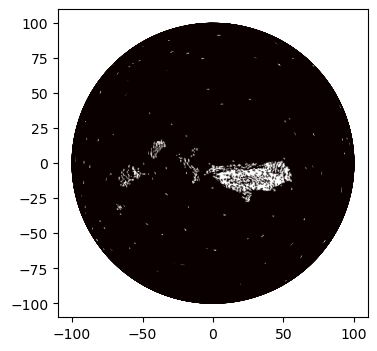

In [12]:
# Using sub, cortex, and the flatmap already loaded in your diagnostic cell earlier
v1v_file = os.path.join(maskinfo_dir, "sub-01_ses-01_hemi-L_desc-V1v-wang_maskinfo.json")
v1v_indices = np.array(json.load(open(v1v_file))['roiIndFsnative']) - 1  # MATLAB -> Python

mask_prop = np.zeros(cortex.vertex_count)
mask_prop[v1v_indices] = 1

import neuropythy as ny
flatmap = cortex.mask_flatmap(('parcellation', 43), map_right='right', radius=np.pi/2)
fmap_with_v1v = flatmap.with_prop(v1v_mask=mask_prop[flatmap.labels])

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(4,4))
ny.cortex_plot(fmap_with_v1v, color='v1v_mask', cmap='hot', axes=ax)
plt.show()

In [13]:
import json
d = json.load(open("/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/sub-01/ses-01/func/sub-01_ses-01_hemi-L_desc-V1v-wang_maskinfo.json"))
print(list(d.keys()))
print("roiIndFsnative length:", len(d['roiIndFsnative']))
print("roiIndBold length:", len(d.get('roiIndBold', [])))
print("roiIndFsnative min/max:", min(d['roiIndFsnative']), max(d['roiIndFsnative']))
print("roiIndBold min/max:", min(d.get('roiIndBold', [0])), max(d.get('roiIndBold', [0])))

['atlas', 'roi', 'hemisphere', 'thisHemiSize', 'boldFiles', 'roiIndFsnative', 'roiIndBold']
roiIndFsnative length: 1246
roiIndBold length: 1246
roiIndFsnative min/max: 2511 128595
roiIndBold min/max: 2437 25191


Unfilled positions: 0


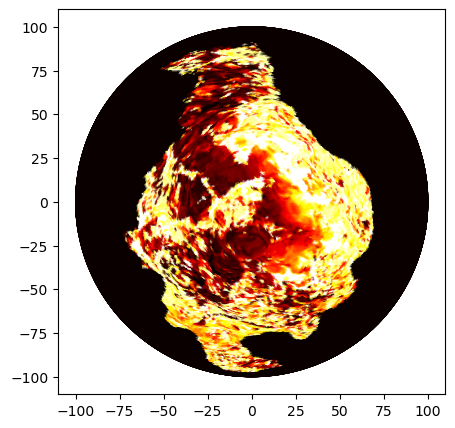

In [14]:
import numpy as np, json, glob, os
import neuropythy as ny
import matplotlib.pyplot as plt

subjects_dir = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/freesurfer-with_t2'
prf_dir = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfanalyze-vista/analysis-02_one_gaussian'
maskinfo_base = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI'

sid, h, hemi_code, prf_session = 'sub-01', 'lh', 'L', 'ses-01'
prf_task, prf_run = 'retCB', 'run-0102avg'

sub = ny.freesurfer_subject(os.path.join(subjects_dir, sid))
cortex = sub.hemis[h]

maskinfo_dir = os.path.join(maskinfo_base, sid, prf_session, 'func')
files = glob.glob(os.path.join(maskinfo_dir, f'{sid}_{prf_session}_hemi-{hemi_code}_desc-*_maskinfo.json'))

vertex_indices = np.full(25260, -1, dtype=int)
for f in files:
    d = json.load(open(f))
    for fs_id, pos in zip(d['roiIndFsnative'], d['roiIndBold']):
        vertex_indices[pos] = fs_id
print("Unfilled positions:", (vertex_indices < 0).sum())

sub_prf_dir = os.path.join(prf_dir, sid, prf_session)
prefix = f'{sid}_{prf_session}_task-{prf_task}_{prf_run}_hemi-{hemi_code}_'
x0_masked = np.asarray(ny.load(os.path.join(sub_prf_dir, prefix + 'centerx0.nii.gz'))).flatten()
y0_masked = np.asarray(ny.load(os.path.join(sub_prf_dir, prefix + 'centery0.nii.gz'))).flatten()

n = cortex.vertex_count
x0_full = np.full(n, np.nan)
y0_full = np.full(n, np.nan)
x0_full[vertex_indices] = x0_masked
y0_full[vertex_indices] = y0_masked
eccentricity = np.sqrt(x0_full**2 + y0_full**2)

flatmap = cortex.mask_flatmap(('parcellation', 43), map_right='right', radius=np.pi/2)
fmap2 = flatmap.with_prop(ecc=eccentricity[flatmap.labels])

fig, ax = plt.subplots(figsize=(5,5))
ny.cortex_plot(fmap2, color='ecc', axes=ax, cmap='hot', vmin=0, vmax=10)
plt.show()

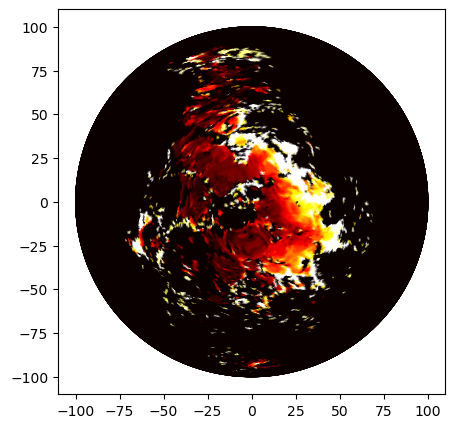

In [15]:
r2_masked = np.asarray(ny.load(os.path.join(sub_prf_dir, prefix + 'r2.nii.gz'))).flatten()
r2_full = np.zeros(n)
r2_full[vertex_indices] = r2_masked

eccentricity_thresholded = np.where(r2_full[flatmap.labels] > 0.1, eccentricity[flatmap.labels], np.nan)
fmap3 = flatmap.with_prop(ecc_thresh=eccentricity_thresholded)

fig, ax = plt.subplots(figsize=(5,5))
ny.cortex_plot(fmap3, color='ecc_thresh', axes=ax, cmap='hot', vmin=0, vmax=10)
plt.show()

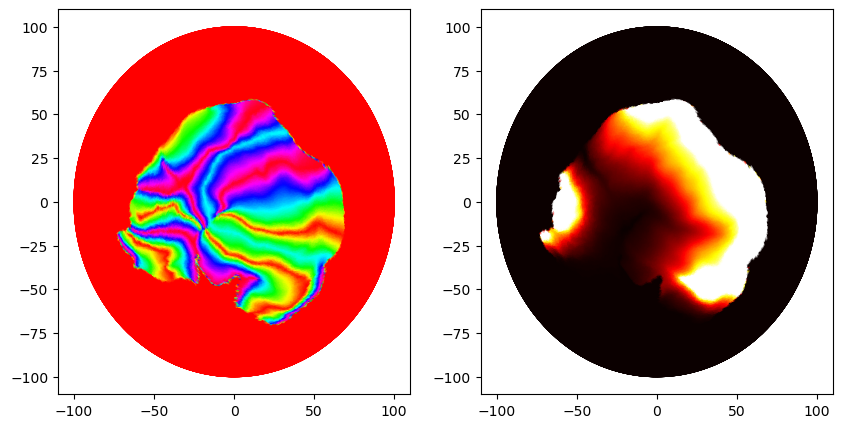

In [16]:
# Test with a benson ROI, this is how it should look like

benson_angle = np.asarray(ny.load(os.path.join(subjects_dir, sid, 'surf', f'{h}.benson14_angle.mgz'))).flatten()
benson_eccen = np.asarray(ny.load(os.path.join(subjects_dir, sid, 'surf', f'{h}.benson14_eccen.mgz'))).flatten()

fmap_ref = flatmap.with_prop(ref_angle=benson_angle[flatmap.labels], ref_eccen=benson_eccen[flatmap.labels])

fig, axes = plt.subplots(1, 2, figsize=(10,5))
ny.cortex_plot(fmap_ref, color='ref_angle', axes=axes[0], cmap='hsv')
ny.cortex_plot(fmap_ref, color='ref_eccen', axes=axes[1], cmap='hot', vmin=0, vmax=10)
plt.show()

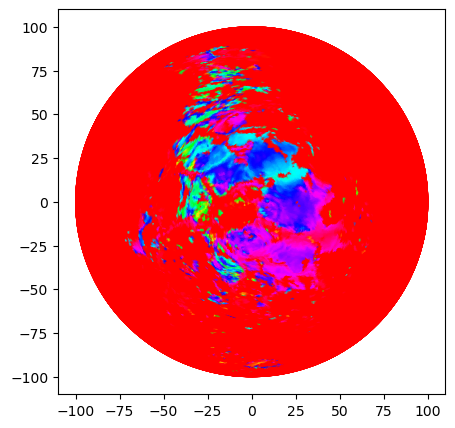

In [17]:
x0_full = np.full(n, np.nan); x0_full[vertex_indices] = x0_masked
y0_full = np.full(n, np.nan); y0_full[vertex_indices] = y0_masked
ang = np.degrees(np.arctan2(y0_full, x0_full))
polar_angle = np.mod(90 - ang + 180, 360) - 180

pa_thresh = np.where(r2_full[flatmap.labels] > 0.1, polar_angle[flatmap.labels], np.nan)
fmap4 = flatmap.with_prop(pa_thresh=pa_thresh)
fig, ax = plt.subplots(figsize=(5,5))
ny.cortex_plot(fmap4, color='pa_thresh', axes=ax, cmap='hsv')
plt.show()

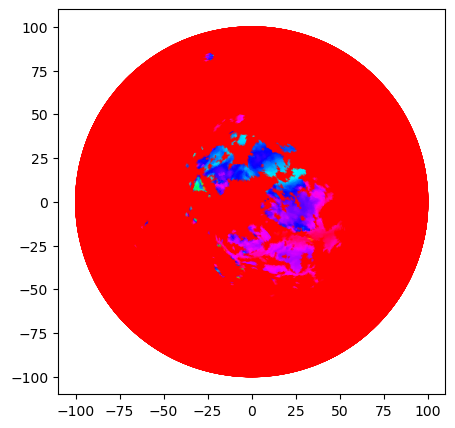

Vertices with R2 > 0.3: 3616 out of 25260 with any fit


In [18]:
pa_thresh_strict = np.where(r2_full[flatmap.labels] > 0.3, polar_angle[flatmap.labels], np.nan)
fmap5 = flatmap.with_prop(pa_strict=pa_thresh_strict)
fig, ax = plt.subplots(figsize=(5,5))
ny.cortex_plot(fmap5, color='pa_strict', axes=ax, cmap='hsv')
plt.show()

# Also worth knowing what fraction of vertices even survive this:
print("Vertices with R2 > 0.3:", (r2_full > 0.3).sum(), "out of", (r2_full > 0).sum(), "with any fit")

In [19]:
import numpy as np, neuropythy as ny
d = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfanalyze-vista/analysis-02_one_gaussian/sub-01/ses-01/'
p = 'sub-01_ses-01_task-retCB_run-0102avg_hemi-L_'
x  = np.asarray(ny.load(d + p + 'centerx0.nii.gz')).flatten()
y  = np.asarray(ny.load(d + p + 'centery0.nii.gz')).flatten()
r2 = np.asarray(ny.load(d + p + 'r2.nii.gz')).flatten()
ecc = np.hypot(x, y)
good = r2 > 0.1
print("well-fit vertices:", good.sum())
print("eccentricity percentiles (50/90/99):", np.percentile(ecc[good], [50, 90, 99]))
print("max:", ecc[good].max())

well-fit vertices: 9969
eccentricity percentiles (50/90/99): [ 3.5557003  15.23996029 19.71850693]
max: 20.624826


In [20]:
import json, numpy as np, neuropythy as ny
d  = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfanalyze-vista/analysis-02_one_gaussian/sub-01/ses-01/'
md = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/sub-01/ses-01/func/'
p  = 'sub-01_ses-01_task-retCB_run-0102avg_hemi-L_'
x  = np.asarray(ny.load(d + p + 'centerx0.nii.gz')).flatten()
y  = np.asarray(ny.load(d + p + 'centery0.nii.gz')).flatten()
r2 = np.asarray(ny.load(d + p + 'r2.nii.gz')).flatten()
ecc = np.hypot(x, y)

pos = []
for roi in ['V1v','V1d','V2v','V2d','V3v','V3d']:
    pos += json.load(open(md + f'sub-01_ses-01_hemi-L_desc-{roi}-wang_maskinfo.json'))['roiIndBold']
pos = np.array(sorted(set(pos)))
e, ok = ecc[pos], r2[pos] > 0.1
print("V1-V3 well-fit vertices:", ok.sum())
print("percentiles (50/75/90/95/99):", np.percentile(e[ok], [50, 75, 90, 95, 99]))
counts, edges = np.histogram(e[ok], bins=np.arange(0, 22, 1))
for c, lo in zip(counts, edges[:-1]):
    print(f"{lo:4.0f}-{lo+1:<4.0f} {c}")

V1-V3 well-fit vertices: 4609
percentiles (50/75/90/95/99): [ 4.54831648  8.59428692 16.59372139 18.62315025 20.09040733]
   0-1    193
   1-2    947
   2-3    502
   3-4    432
   4-5    441
   5-6    316
   6-7    248
   7-8    291
   8-9    183
   9-10   118
  10-11   62
  11-12   73
  12-13   63
  13-14   86
  14-15   54
  15-16   79
  16-17   107
  17-18   127
  18-19   112
  19-20   127
  20-21   48


In [21]:
import scipy.io as sio, numpy as np
d = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfanalyze-vista/analysis-02_one_gaussian/sub-01/ses-01/'
mat = sio.loadmat(d + 'sub-01_ses-01_task-retCB_run-0102avg_hemi-L_results.mat', simplify_cells=True)

def walk(o, path=''):
    if isinstance(o, dict):
        for k, v in o.items():
            walk(v, f'{path}/{k}')
    else:
        try:
            a = np.asarray(o)
            print(path, a if a.size <= 10 else f'array{a.shape}')
        except Exception:
            print(path, type(o))

walk(mat['results']['params'])

/analysis/pRFmodel one gaussian
/analysis/numberStimulusGridPoints 101
/analysis/calcPC 1
/analysis/nSlices 1
/analysis/session pRFsynthetic01
/analysis/dataType Original
/analysis/scans 1
/analysis/viewType Inplane
/analysis/dc/datadriven 0
/analysis/dc/hrfTime 22
/analysis/betaRatioAlpha 1
/analysis/sigmaRatioFixedValue [1 1 1]
/analysis/fixcssexp 0
/analysis/keepAllPoints 0
/analysis/minFieldSize 0
/analysis/fieldSize 9
/analysis/Hrf array(26,)
/analysis/HrfMaxResponse 0.26802520426859094
/analysis/coarseToFine 0
/analysis/coarseSample 0
/analysis/coarseBlurParams [10.    0.75]
/analysis/linkBlurParams [5.  1.1]
/analysis/coarseDecimate 2
/analysis/numberSigmas 24
/analysis/minRF 0.2
/analysis/numberSigmaRatios 5
/analysis/numberThetas 4
/analysis/spaceSigmas linlog
/analysis/linlogcutoff 0.7
/analysis/scaleWithSigmas 0
/analysis/minimumGridSampling 7
/analysis/relativeGridStep 2.3548200450309493
/analysis/outerlimit 2
/analysis/sigmaRatio array(12,)
/analysis/minSigmaRatio 1
/analy

In [22]:
import json, numpy as np, neuropythy as ny
sid = 'sub-11'
d  = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfanalyze-vista/analysis-02_one_gaussian/{sid}/ses-01/'
md = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/{sid}/ses-01/func/'
for hemi in ['L', 'R']:
    p  = f'{sid}_ses-01_task-retCB_run-0102avg_hemi-{hemi}_'
    x  = np.asarray(ny.load(d + p + 'centerx0.nii.gz')).flatten()
    y  = np.asarray(ny.load(d + p + 'centery0.nii.gz')).flatten()
    r2 = np.asarray(ny.load(d + p + 'r2.nii.gz')).flatten()
    ok = (r2 > 0.1) & (np.hypot(x, y) < 9)
    for roi in ['V1v', 'V1d']:
        pos = np.array(json.load(open(md + f'{sid}_ses-01_hemi-{hemi}_desc-{roi}-wang_maskinfo.json'))['roiIndBold'])
        s = ok[pos]
        print(f"{hemi} {roi}: n={s.sum()}  mean x0={x[pos][s].mean():.2f}  mean y0={y[pos][s].mean():.2f}")

L V1v: n=925  mean x0=3.18  mean y0=-0.61
L V1d: n=774  mean x0=2.23  mean y0=2.73
R V1v: n=804  mean x0=-2.90  mean y0=-0.53
R V1d: n=998  mean x0=-1.87  mean y0=2.23


In [23]:
help(cortex.mask_flatmap)

Help on method mask_flatmap in module neuropythy.geometry.mesh:

mask_flatmap(mask, map_right='anterior', radius=Ellipsis, method=Ellipsis, pre_affine=Ellipsis, post_affine=Ellipsis, meta_data=Ellipsis, registration='native') method of neuropythy.mri.core.Cortex instance
    hemi.mask_flatmap(mask) yields a flatmap of the given hemisphere that is centered on the
      middle of the given mask.
    
    The following options may be given:
      * radius (default: Ellipsis) is passed along to the map_projection() function.
      * method (default: Ellipsis) is passed along to the map_projection() function.
      * pre_affine (default: Ellipsis) is passed along to the map_projection() function.
      * post_affine (default: Ellipsis) is passed along to the map_projection() function.
      * meta_data (default: Ellipsis) is passed along to the map_projection() function.
      * map_right (default: 'anterior') may be a direction ('anterior', 'posterior', 'inferior',
        'superior', 'lef

In [24]:
import glob, json
base = '/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI'
for hc in ['L', 'R']:
    for pat in ['V3*', 'IPS*']:
        for f in sorted(glob.glob(f'{base}/sub-04/ses-*/func/*_hemi-{hc}_desc-{pat}-wang_maskinfo.json')):
            n = len(json.load(open(f))['roiIndFsnative'])
            print(hc, f.split('/')[-3], f.split('desc-')[1].replace('_maskinfo.json', ''), n)

L ses-01 V3a-wang 22
L ses-01 V3b-wang 377
L ses-01 V3d-wang 812
L ses-01 V3v-wang 809
L ses-02 V3a-wang 22
L ses-02 V3b-wang 377
L ses-02 V3d-wang 812
L ses-02 V3v-wang 809
L ses-03 V3a-wang 22
L ses-03 V3b-wang 377
L ses-03 V3d-wang 812
L ses-03 V3v-wang 809
L ses-04 V3a-wang 22
L ses-04 V3b-wang 377
L ses-04 V3d-wang 812
L ses-04 V3v-wang 809
L ses-05 V3a-wang 22
L ses-05 V3b-wang 377
L ses-05 V3d-wang 812
L ses-05 V3v-wang 809
L ses-06 V3a-wang 22
L ses-06 V3b-wang 377
L ses-06 V3d-wang 812
L ses-06 V3v-wang 809
L ses-07 V3a-wang 22
L ses-07 V3b-wang 377
L ses-07 V3d-wang 812
L ses-07 V3v-wang 809
L ses-08 V3a-wang 22
L ses-08 V3b-wang 377
L ses-08 V3d-wang 812
L ses-08 V3v-wang 809
L ses-09 V3a-wang 22
L ses-09 V3b-wang 377
L ses-09 V3d-wang 812
L ses-09 V3v-wang 809
L ses-10 V3a-wang 22
L ses-10 V3b-wang 377
L ses-10 V3d-wang 812
L ses-10 V3v-wang 809
L ses-01 IPS0-wang 835
L ses-01 IPS1-wang 630
L ses-01 IPS2-wang 520
L ses-01 IPS3-wang 331
L ses-01 IPS4-wang 73
L ses-01 IPS5-wa

In [25]:
import glob, json, os, numpy as np, neuropythy as ny
sid, ses = 'sub-04', 'ses-01'
fs = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/freesurfer-with_t2/{sid}'
base = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/{sid}/{ses}/func'
sub = ny.freesurfer_subject(fs)
for hc, h in [('L', 'lh'), ('R', 'rh')]:
    cx = sub.hemis[h]
    n = cx.vertex_count
    u, v = cx.tess.indexed_edges
    rois = {}
    for f in sorted(glob.glob(f'{base}/{sid}_{ses}_hemi-{hc}_desc-*-wang_maskinfo.json')):
        name = os.path.basename(f).split('desc-')[1].replace('-wang_maskinfo.json', '')
        m = np.zeros(n, bool)
        m[json.load(open(f))['roiIndFsnative']] = True
        rois[name] = m
    print(hc, 'ROIs found:', list(rois))
    for a in ['V3a', 'V3b']:
        touching = {b: int(np.sum((rois[a][u] & rois[b][v]) | (rois[b][u] & rois[a][v])))
                    for b in rois if b != a}
        print(hc, a, 'edges shared with:', {b: c for b, c in touching.items() if c > 0})

L ROIs found: ['IPS0', 'IPS1', 'IPS2', 'IPS3', 'IPS4', 'IPS5', 'LO1', 'LO2', 'OWA', 'PHC1', 'PHC2', 'SPL1', 'TO1', 'TO2', 'V1d', 'V1v', 'V2d', 'V2v', 'V3a', 'V3b', 'V3d', 'V3v', 'VO1', 'VO2', 'aOTS', 'hFEF', 'hV4', 'mFus', 'mOTS', 'pOTS']
L V3a edges shared with: {'V3b': 13}
L V3b edges shared with: {'LO1': 59, 'V3a': 13}
R ROIs found: ['IPS0', 'IPS1', 'IPS2', 'IPS3', 'IPS4', 'IPS5', 'LO1', 'LO2', 'PHC1', 'PHC2', 'SPL1', 'TO1', 'TO2', 'V1d', 'V1v', 'V2d', 'V2v', 'V3a', 'V3b', 'V3d', 'V3v', 'VO1', 'VO2', 'hFEF', 'hV4']
R V3a edges shared with: {'V3b': 55}
R V3b edges shared with: {'LO1': 75, 'V3a': 55}


In [26]:
import glob, json, os, numpy as np, neuropythy as ny
sid, ses = 'sub-04', 'ses-01'
fs = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/freesurfer-with_t2/{sid}'
base = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/{sid}/{ses}/func'
wang = ['V1v','V1d','V2v','V2d','V3v','V3d','hV4','VO1','VO2','PHC1','PHC2','TO2','TO1',
        'LO2','LO1','V3b','V3a','IPS0','IPS1','IPS2','IPS3','IPS4','IPS5','SPL1','hFEF']
sub = ny.freesurfer_subject(fs)
for hc, h in [('L', 'lh'), ('R', 'rh')]:
    cx = sub.hemis[h]
    n = cx.vertex_count
    u, v = cx.tess.indexed_edges
    rois = {}
    for name in wang:
        f = f'{base}/{sid}_{ses}_hemi-{hc}_desc-{name}-wang_maskinfo.json'
        if os.path.isfile(f):
            m = np.zeros(n, bool)
            m[json.load(open(f))['roiIndFsnative']] = True
            rois[name] = m
    def touch(a):
        t = {b: int(np.sum((rois[a][u] & rois[b][v]) | (rois[b][u] & rois[a][v])))
             for b in rois if b != a}
        return {b: c for b, c in t.items() if c > 0}
    unlabeled = ~np.any(list(rois.values()), axis=0)
    def grow(seed, steps=15):
        cur = seed.copy()
        for _ in range(steps):
            nxt = cur.copy()
            nxt[v[cur[u] & unlabeled[v]]] = True
            nxt[u[cur[v] & unlabeled[u]]] = True
            cur = nxt
        return cur & unlabeled
    gap = grow(rois['V3d']) & grow(rois['IPS0'])
    print(hc, 'V3d touches:', touch('V3d'))
    print(hc, 'IPS0 touches:', touch('IPS0'))
    print(hc, 'unlabeled vertices reachable from both V3d and IPS0:', int(gap.sum()))

L V3d touches: {'V2d': 131, 'TO2': 93, 'TO1': 20, 'LO2': 64}
L IPS0 touches: {'TO2': 74, 'TO1': 37, 'IPS1': 137}
L unlabeled vertices reachable from both V3d and IPS0: 140
R V3d touches: {'V2d': 176, 'TO2': 97, 'TO1': 22, 'LO2': 67}
R IPS0 touches: {'TO2': 99, 'TO1': 49, 'IPS1': 154}
R unlabeled vertices reachable from both V3d and IPS0: 105


In [27]:
import os, json, numpy as np, pandas as pd, neuropythy as ny
sid, ses = 'sub-04', 'ses-01'
fs = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/freesurfer-with_t2/{sid}'
base = f'/bcbl/home/public/Gari/VOTCLOC/main_exp/BIDS/derivatives/prfprepare/analysis-02_votcROI/{sid}/{ses}/func'
group = ['V2d', 'V3d', 'V3a', 'V3b', 'LO1', 'LO2', 'TO1', 'TO2', 'IPS0', 'IPS1']
sub = ny.freesurfer_subject(fs)
for hc, h in [('L', 'lh'), ('R', 'rh')]:
    cx = sub.hemis[h]
    n = cx.vertex_count
    u, v = cx.tess.indexed_edges
    rois = {}
    for name in group:
        f = f'{base}/{sid}_{ses}_hemi-{hc}_desc-{name}-wang_maskinfo.json'
        m = np.zeros(n, bool)
        m[json.load(open(f))['roiIndFsnative']] = True
        rois[name] = m
    print(hc, 'vertex counts:', {k: int(m.sum()) for k, m in rois.items()})
    M = [[0 if a == b else int(np.sum((rois[a][u] & rois[b][v]) | (rois[b][u] & rois[a][v])))
          for b in group] for a in group]
    print(pd.DataFrame(M, index=group, columns=group))

L vertex counts: {'V2d': 963, 'V3d': 812, 'V3a': 22, 'V3b': 377, 'LO1': 301, 'LO2': 461, 'TO1': 382, 'TO2': 661, 'IPS0': 835, 'IPS1': 630}
      V2d  V3d  V3a  V3b  LO1  LO2  TO1  TO2  IPS0  IPS1
V2d     0  131    0    0    0    0    0    0     0     0
V3d   131    0    0    0    0   64   20   93     0     0
V3a     0    0    0   13    0    0    0    0     0     0
V3b     0    0   13    0   59    0    0    0     0     0
LO1     0    0    0   59    0   73    8    0     0     0
LO2     0   64    0    0   73    0   60    0     0     0
TO1     0   20    0    0    8   60    0   48    37     0
TO2     0   93    0    0    0    0   48    0    74     0
IPS0    0    0    0    0    0    0   37   74     0   137
IPS1    0    0    0    0    0    0    0    0   137     0
R vertex counts: {'V2d': 1182, 'V3d': 796, 'V3a': 147, 'V3b': 431, 'LO1': 283, 'LO2': 601, 'TO1': 482, 'TO2': 785, 'IPS0': 729, 'IPS1': 594}
      V2d  V3d  V3a  V3b  LO1  LO2  TO1  TO2  IPS0  IPS1
V2d     0  176    0    0    0    0  